Task 4 Sentiment Analysis

In [1]:
import os

# Set project folder path
project_path = r"C:\Users\Aditi\OneDrive\Desktop\CodeAlpha_SentimentAnalysis"

# Check folder
os.chdir(project_path)

print("Current Folder:", os.getcwd())
print("\nAvailable Files:")
print(os.listdir())


Current Folder: C:\Users\Aditi\OneDrive\Desktop\CodeAlpha_SentimentAnalysis

Available Files:
['Amazon_Reviews_Dataset.csv', 'Chart_4_Sentiment_Analysis.png', 'CodeAlpha_Reviews_Dataset.csv', 'CodeAlpha_SentimentAnalysis_Option1.ipynb', 'CodeAlpha_SentimentAnalysis_Option2.ipynb', 'Option2_Emotion_Distribution.csv', 'Option2_Sentiment_Analysis_Results.csv', 'README.md', 'requirements.txt', 'visualizations']


Load Dataset

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Amazon Reviews Dataset
df = pd.read_csv("Amazon_Reviews_Dataset.csv")

# Display first 5 records
print("First 5 Reviews:")
display(df.head())

# Dataset Shape
print("\nDataset Shape:", df.shape)

# Column Names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset Information
print("\nDataset Information:")
df.info()


First 5 Reviews:


,review_text,label
0,Excellent product! I love reading through the ...,positive
1,"If you into gaming, into the latest PC tech in...",positive
2,Great Mag..!!,positive
3,"Extremely similar to GQ, same publisher. You a...",positive
4,it is great read and great ideas for today's m...,positive



Dataset Shape: (5000, 2)

Column Names:
['review_text', 'label']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_text  5000 non-null   str  
 1   label        5000 non-null   str  
dtypes: str(2)
memory usage: 78.3 KB


Check Sentiment Distribution

Sentiment Distribution:
label
positive    3092
negative    1908
Name: count, dtype: int64


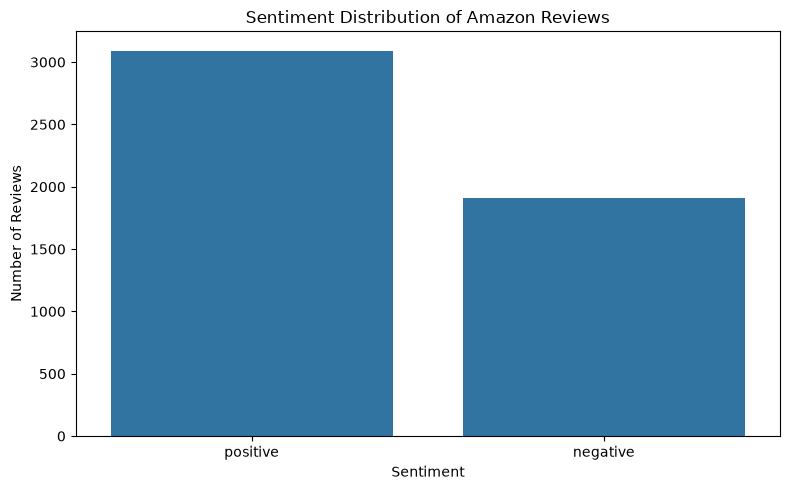

In [3]:
# Count sentiment labels
print("Sentiment Distribution:")
print(df['label'].value_counts())

# Visualize sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='label')

plt.title("Sentiment Distribution of Amazon Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.savefig(
    "visualizations/Option2/Sentiment_Distribution.png",
    bbox_inches="tight"
)
plt.show()

VADER Sentiment Analysis

In [4]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# Function to detect sentiment
def get_sentiment(text):
    scores = analyzer.polarity_scores(str(text))
    
    if scores['compound'] >= 0.05:
        return 'positive'
    elif scores['compound'] <= -0.05:
        return 'negative'
    else:
        return 'neutral'

# Apply sentiment analysis
df['vader_sentiment'] = df['review_text'].apply(get_sentiment)

# Display results
display(df[['review_text', 'label', 'vader_sentiment']].head(10))

# Count predicted sentiments
print("\nVADER Sentiment Results:")
print(df['vader_sentiment'].value_counts())


,review_text,label,vader_sentiment
0,Excellent product! I love reading through the ...,positive,positive
1,"If you into gaming, into the latest PC tech in...",positive,positive
2,Great Mag..!!,positive,positive
3,"Extremely similar to GQ, same publisher. You a...",positive,neutral
4,it is great read and great ideas for today's m...,positive,positive
5,Very dissapointed. I love this magazine and wa...,positive,positive
6,Allure sent me 3 magazines in the space of a m...,negative,negative
7,Minimal content. A very diffrent magazine than...,negative,neutral
8,This magazine doesn't really have much to it. ...,positive,positive
9,A must for all bottom-dwellers,positive,neutral



VADER Sentiment Results:
vader_sentiment
positive    3015
negative    1115
neutral      870
Name: count, dtype: int64


Actual vs Predicted Sentiment Comparison

VADER Model Accuracy: 67.12 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.76      0.44      0.56      1908
     neutral       0.00      0.00      0.00         0
    positive       0.83      0.81      0.82      3092

    accuracy                           0.67      5000
   macro avg       0.53      0.42      0.46      5000
weighted avg       0.80      0.67      0.72      5000



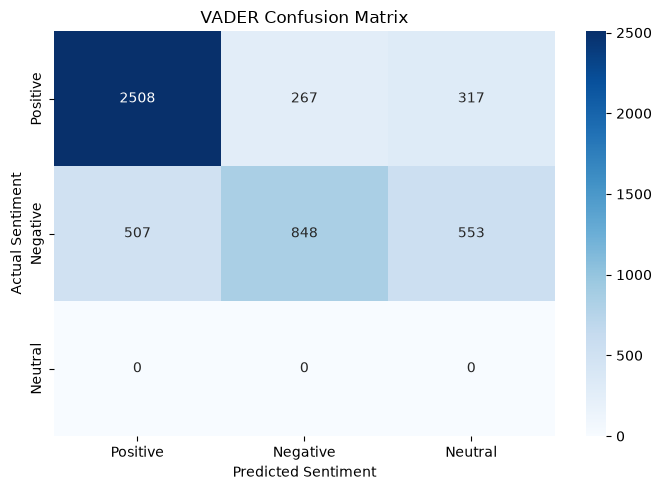

In [5]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Actual and predicted labels
y_true = df['label'].str.lower()
y_pred = df['vader_sentiment']

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print("VADER Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=['positive', 'negative', 'neutral']
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Positive', 'Negative', 'Neutral'],
    yticklabels=['Positive', 'Negative', 'Neutral']
)

plt.title("VADER Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.savefig(
    "visualizations/Option2/VADER_Confusion_Matrix.png",
    bbox_inches="tight"
)

plt.show()

Emotion Detection using NRCLex

In [6]:

import re
from collections import Counter
from nrclex import NRCLex

# Load NRC Emotion Lexicon
emotion_analyzer = NRCLex()

# Detect emotions from text
def detect_emotions(text):
    words = re.findall(r'\b\w+\b', str(text).lower())
    emotion_scores = Counter()

    for word in words:
        emotions = emotion_analyzer.__lexicon__.get(word, [])
        emotion_scores.update(emotions)

    return dict(emotion_scores)

# Apply emotion detection
df['emotions'] = df['review_text'].apply(detect_emotions)

# Display first 10 results
display(df[['review_text', 'emotions']].head(10))

print("Emotion Detection Completed Successfully!")


,review_text,emotions
0,Excellent product! I love reading through the ...,"{'joy': 2, 'positive': 6, 'trust': 1}"
1,"If you into gaming, into the latest PC tech in...",{'positive': 1}
2,Great Mag..!!,{}
3,"Extremely similar to GQ, same publisher. You a...","{'positive': 2, 'trust': 2, 'joy': 1}"
4,it is great read and great ideas for today's m...,{}
5,Very dissapointed. I love this magazine and wa...,"{'joy': 1, 'positive': 2}"
6,Allure sent me 3 magazines in the space of a m...,"{'anticipation': 1, 'joy': 1, 'positive': 1, '..."
7,Minimal content. A very diffrent magazine than...,"{'joy': 1, 'positive': 1, 'trust': 1}"
8,This magazine doesn't really have much to it. ...,"{'anticipation': 1, 'joy': 1, 'positive': 1}"
9,A must for all bottom-dwellers,"{'negative': 1, 'sadness': 1}"


Emotion Detection Completed Successfully!


Emotion Visualization

Emotion Distribution:


,Emotion,Count
1,positive,6405
0,joy,3526
2,trust,3052
3,anticipation,2578
7,negative,1664
4,surprise,1151
8,sadness,773
6,disgust,628
5,anger,627
9,fear,488


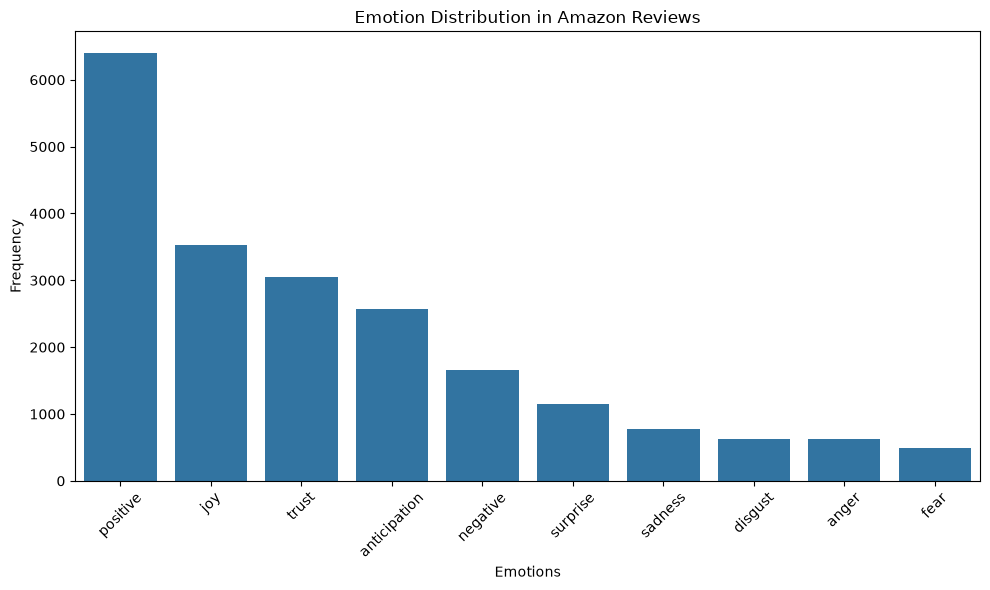

In [7]:

from collections import Counter

# Count all detected emotions
all_emotions = Counter()

for emotion_dict in df['emotions']:
    all_emotions.update(emotion_dict)

# Convert to DataFrame
emotion_df = pd.DataFrame(
    all_emotions.items(),
    columns=['Emotion', 'Count']
)

emotion_df = emotion_df.sort_values(
    by='Count', ascending=False
)

# Display emotion counts
print("Emotion Distribution:")
display(emotion_df)

# Plot emotion distribution
plt.figure(figsize=(10, 6))

sns.barplot(
    data=emotion_df,
    x='Emotion',
    y='Count'
)

plt.title("Emotion Distribution in Amazon Reviews")
plt.xlabel("Emotions")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "visualizations/Option2/Emotion_Distribution.png",
    bbox_inches="tight"
)
plt.show()



Sentiment Pie Chart

Sentiment Percentages:
vader_sentiment
positive    60.3
negative    22.3
neutral     17.4
Name: count, dtype: float64


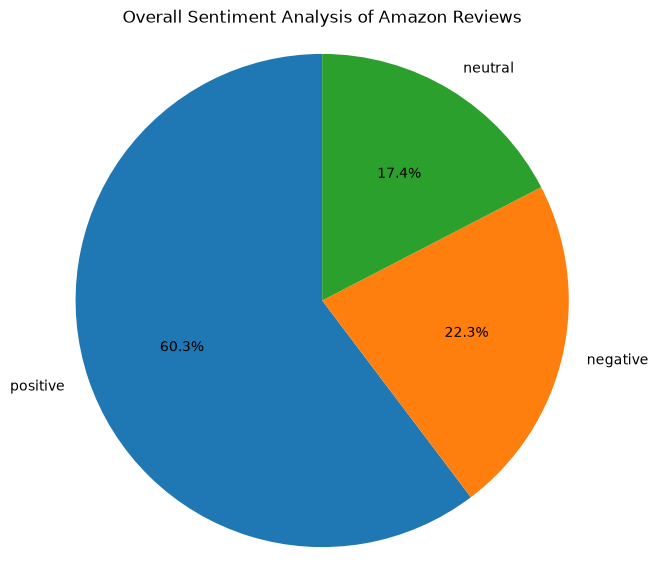

In [16]:
# Count sentiments
sentiment_counts = df['vader_sentiment'].value_counts()

# Display percentages
print("Sentiment Percentages:")
print((sentiment_counts / len(df) * 100).round(2))

# Pie Chart
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Overall Sentiment Analysis of Amazon Reviews")
plt.axis('equal')

plt.savefig(
    "visualizations/Option2/Chart_4_Sentiment_Analysis.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

In [17]:

# Final Sentiment Analysis Results

total_reviews = len(df)

print("=" * 50)
print("FINAL SENTIMENT ANALYSIS RESULTS")
print("=" * 50)

print("\nTotal Reviews Analyzed:", total_reviews)

print("\nVADER Sentiment Results:")
print(df['vader_sentiment'].value_counts())

print("\nEmotion Analysis:")
display(emotion_df)

print("\nModel Accuracy:",
      round(accuracy * 100, 2), "%")

print("\nCONCLUSION:")
print("""
Sentiment analysis was successfully performed on Amazon reviews
using VADER sentiment analysis and NRC Emotion Lexicon.

Reviews were classified into Positive, Negative and Neutral
categories.

Emotion detection identified emotions such as Joy, Sadness,
Anger, Fear, Trust and Anticipation.

The analysis helps understand customer opinions and emotions.
These insights can support marketing strategies and product
development.
""")


FINAL SENTIMENT ANALYSIS RESULTS

Total Reviews Analyzed: 5000

VADER Sentiment Results:
vader_sentiment
positive    3015
negative    1115
neutral      870
Name: count, dtype: int64

Emotion Analysis:


,Emotion,Count
1,positive,6405
0,joy,3526
2,trust,3052
3,anticipation,2578
7,negative,1664
4,surprise,1151
8,sadness,773
6,disgust,628
5,anger,627
9,fear,488



Model Accuracy: 67.12 %

CONCLUSION:

Sentiment analysis was successfully performed on Amazon reviews
using VADER sentiment analysis and NRC Emotion Lexicon.

Reviews were classified into Positive, Negative and Neutral
categories.

Emotion detection identified emotions such as Joy, Sadness,
Anger, Fear, Trust and Anticipation.

The analysis helps understand customer opinions and emotions.
These insights can support marketing strategies and product
development.



In [18]:

# Save final analysis results
df.to_csv("Option2_Sentiment_Analysis_Results.csv", index=False)

# Save emotion distribution
emotion_df.to_csv("Option2_Emotion_Distribution.csv", index=False)

print("All Results Saved Successfully!")


All Results Saved Successfully!


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import os

print(os.listdir())

['Amazon_Reviews_Dataset.csv', 'Chart_4_Sentiment_Analysis.png', 'CodeAlpha_Reviews_Dataset.csv', 'CodeAlpha_SentimentAnalysis_Option1.ipynb', 'CodeAlpha_SentimentAnalysis_Option2.ipynb', 'Option2_Emotion_Distribution.csv', 'Option2_Sentiment_Analysis_Results.csv', 'README.md', 'requirements.txt', 'visualizations']


In [20]:
import os

os.makedirs("visualizations/Option2", exist_ok=True)

print("Option 2 Visualizations Folder Created!")

Option 2 Visualizations Folder Created!


In [21]:
plt.savefig("visualizations/Option2/GRAPH_NAME.png",
            bbox_inches="tight")

<Figure size 640x480 with 0 Axes>